In [1]:
# Library untuk pengolahan data
import pandas as pd
import numpy as np

# Library untuk membagi dataset
from sklearn.model_selection import train_test_split

# Library untuk preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Library untuk model Logistic Regression
from sklearn.linear_model import LogisticRegression

# Library untuk evaluasi model klasifikasi
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Memuat dataset yang sudah dibersihkan
df = pd.read_csv("../data/processed/cardio_cleaned.csv")

# Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# Menampilkan 5 baris pertama
df.head()

Ukuran dataset: (68652, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=["id", "cardio"])
y = df["cardio"]

# Memeriksa ukuran X dan y
print("Ukuran fitur (X):", X.shape)
print("Ukuran target (y):", y.shape)

# Melihat daftar fitur
print("\nDaftar fitur:")
print(X.columns.tolist())

# Melihat distribusi target
print("\nDistribusi target:")
print(y.value_counts())

Ukuran fitur (X): (68652, 11)
Ukuran target (y): (68652,)

Daftar fitur:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Distribusi target:
cardio
0    34689
1    33963
Name: count, dtype: int64


In [4]:
# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Memeriksa ukuran data
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

# Memeriksa distribusi target setelah pembagian
print("\nDistribusi target pada data training:")
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribusi target pada data testing:")
print(y_test.value_counts(normalize=True) * 100)

Ukuran X_train: (54921, 11)
Ukuran X_test: (13731, 11)
Ukuran y_train: (54921,)
Ukuran y_test: (13731,)

Distribusi target pada data training:
cardio
0    50.528942
1    49.471058
Name: proportion, dtype: float64

Distribusi target pada data testing:
cardio
0    50.528002
1    49.471998
Name: proportion, dtype: float64


In [5]:
# Menentukan fitur kategorikal
categorical_features = ["gender"]

# Menentukan fitur numerik
numeric_features = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

In [6]:
# Membuat preprocessing menggunakan ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [7]:
# Fit preprocessing pada data training dan transform data training
X_train_processed = preprocessor.fit_transform(X_train)

# Transform data testing menggunakan preprocessing dari data training
X_test_processed = preprocessor.transform(X_test)

# Memeriksa ukuran data setelah preprocessing
print("Ukuran X_train setelah preprocessing:", X_train_processed.shape)
print("Ukuran X_test setelah preprocessing:", X_test_processed.shape)

Ukuran X_train setelah preprocessing: (54921, 12)
Ukuran X_test setelah preprocessing: (13731, 12)


In [8]:
# Membuat model Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Melatih model menggunakan data training
logistic_model.fit(X_train_processed, y_train)

print("Model Logistic Regression berhasil dilatih!")

Model Logistic Regression berhasil dilatih!


In [9]:
# Melakukan prediksi kelas pada data testing
y_pred = logistic_model.predict(X_test_processed)

# Menghitung probabilitas untuk kelas 1
y_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

# Membandingkan hasil aktual dan prediksi
comparison = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred,
    "Probabilitas Kelas 1": y_proba
})

# Menampilkan 10 hasil pertama
display(comparison.head(10))

# Memeriksa jumlah prediksi
print("Jumlah hasil prediksi:", len(y_pred))

,Aktual,Prediksi,Probabilitas Kelas 1
0,1,1,0.541347
1,1,1,0.640771
2,1,1,0.702709
3,1,1,0.678685
4,1,1,0.773123
5,1,0,0.272282
6,0,0,0.458387
7,1,0,0.256133
8,0,1,0.540037
9,0,1,0.913774


Jumlah hasil prediksi: 13731


In [10]:
# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

# Menampilkan hasil evaluasi
print("Hasil Evaluasi Logistic Regression")
print("----------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Hasil Evaluasi Logistic Regression
----------------------------------
Accuracy : 0.7218
Precision: 0.7512
Recall   : 0.6544
F1-Score : 0.6994
ROC-AUC  : 0.7841


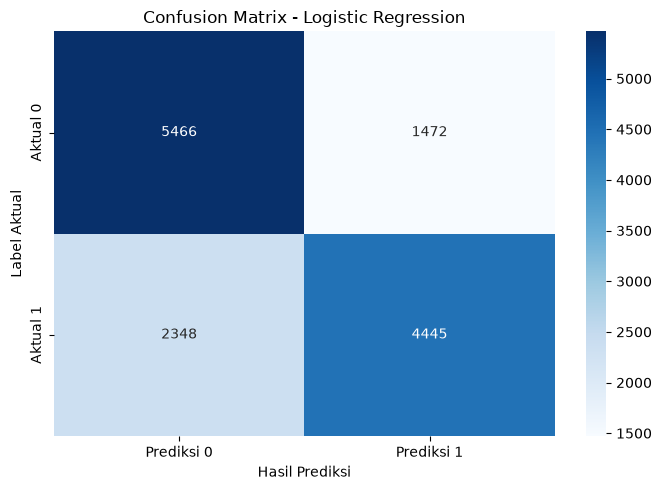

[[5466 1472]
 [2348 4445]]


In [11]:
# Menghitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Membuat visualisasi Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Prediksi 0", "Prediksi 1"],
    yticklabels=["Aktual 0", "Aktual 1"]
)

plt.xlabel("Hasil Prediksi")
plt.ylabel("Label Aktual")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print(cm)

In [12]:
# Menampilkan Classification Report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Kelas 0", "Kelas 1"]
    )
)

              precision    recall  f1-score   support

     Kelas 0       0.70      0.79      0.74      6938
     Kelas 1       0.75      0.65      0.70      6793

    accuracy                           0.72     13731
   macro avg       0.73      0.72      0.72     13731
weighted avg       0.73      0.72      0.72     13731



In [13]:
from sklearn.metrics import roc_curve

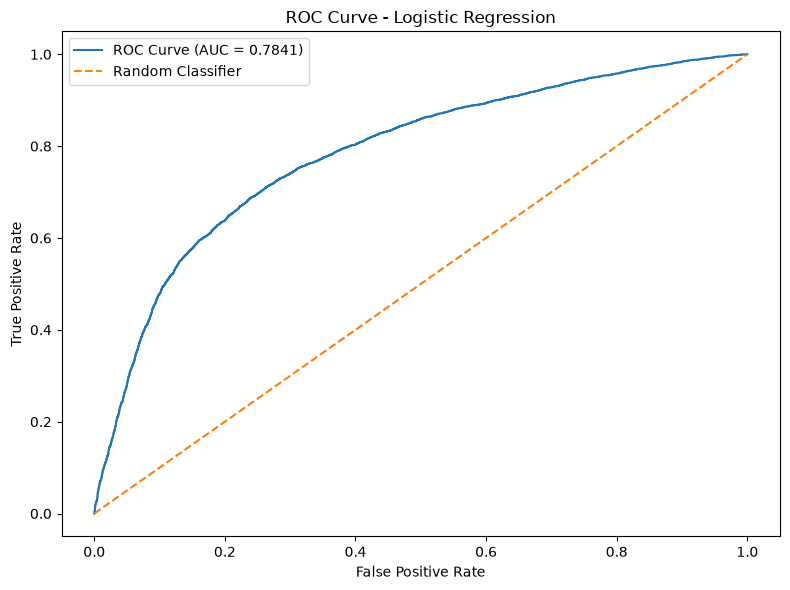

In [14]:
# Menghitung nilai False Positive Rate dan True Positive Rate
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Membuat visualisasi ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.4f})"
)

# Garis pembanding klasifikasi acak
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Kesimpulan

Model Logistic Regression berhasil dibangun untuk melakukan klasifikasi terhadap target `cardio` menggunakan 11 fitur dari dataset Cardiovascular Disease.

Dataset yang telah dibersihkan terdiri dari 68.652 baris data, kemudian dibagi menjadi 80% data training dan 20% data testing.

Evaluasi model pada 13.731 data testing menghasilkan:

- Accuracy: 72,18%
- Precision: 75,12%
- Recall: 65,44%
- F1-Score: 69,94%
- ROC-AUC: 0,7841

Berdasarkan Confusion Matrix, model berhasil mengklasifikasikan 5.466 data kelas 0 dan 4.445 data kelas 1 dengan benar.

Classification Report menunjukkan bahwa model memiliki Recall lebih tinggi pada kelas 0 (79%) dibandingkan kelas 1 (65%). Hal ini menunjukkan bahwa model lebih baik dalam mengenali kelas 0 dibandingkan kelas 1.

Nilai ROC-AUC sebesar 0,7841 menunjukkan bahwa model memiliki kemampuan yang cukup baik dalam membedakan kedua kelas.

Secara keseluruhan, Logistic Regression berhasil mempelajari pola klasifikasi dari dataset, meskipun performanya masih dapat ditingkatkan. Model ini digunakan untuk keperluan pembelajaran machine learning dan bukan sebagai alat diagnosis medis.